# Lecture 28 notebook: part-time strategies

This notebook replays Lecture 28. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process. The data are free: Lecture 27's baseline (built by its notebook), FRED series (VIX, VXO, the Fed's target, the yield curve, the dollar, Treasury yields, exchange rates, oil and gas prices), the Philadelphia Fed's Real-Time Data Set (industrial production and CPI as first published), equity indices from Yahoo Finance, and the capstone futures of Lecture 11 (local, not committed). Downloads are saved once in `data/raw/l28_realtime`.

By default the notebook builds the regime series if they are not there yet, redraws every figure of the lecture as `figures/nb_*.png` from the shipped results, and checks the lecture's mechanics by hand. `RUN_ALL` also reruns every analysis (one script at a time) and compares the key numbers with the shipped ones. Recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | |
| 1 | The key chart; the switch by hand | §1 |
| 2 | Comparing part-time with always-in: the six numbers, random filters and the square-root link by hand | §2 |
| 3 | Data as first published: the share of days in another quadrant, by hand | §3 |
| 4 | The scan | §4 |
| 5 | The filters against luck; Benjamini-Hochberg by hand | §5 |
| 6 | Why: Fed and dollar, level and direction, quadrants, clock, timeline, 1990-2005 | §6 |
| 7 | Commodity curves; one curve gap by hand | §7 |
| 8 | Shipped against recomputed; a test of your own | |

## 0. Settings and data

In [1]:
import json, os, re, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l28 as L
import l28_filters as LF
L26, L25 = L.L26, L.L25
RUN_ALL = False                                                            # True: also rerun every analysis

SHIPPED = HERE / "results"; WORK = L25.DATA / "l28_results"               # recomputed results go to WORK, never over the shipped ones
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
FUTURES = L.FT.CACHE.exists()
print("data:", L.OUT, "| shipped results:", SHIPPED, "| recomputed results:", WORK, "| capstone futures found:", FUTURES)


def run(script, *args, show=False):
    "Run a script of this lecture in a fresh process; figures as nb_*, results to WORK."
    t0 = time.time()
    env = {**os.environ, "PORTFOLIO_DATA": str(L25.DATA), "L28_RESULTS": str(WORK), "L28_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))

data: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l28 | shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\28-part-time-strategies\results | recomputed results: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l28_results | capstone futures found: True


**The data.** `l28.py` builds the two baselines' daily returns (ETFs from Lecture 27; the capstone futures with Lecture 27's rules) and every regime series, known the day before: macro data as first published and as revised today, the Fed on hold, and the market-state measures with their thresholds. It needs Lecture 27's daily results and the capstone futures.

In [2]:
if not (L.OUT / "l28_base.parquet").exists(): run("l28.py", show=True)
B = pd.read_parquet(L.OUT / "l28_base.parquet")
for tag, start in (("etf", L.ETF_START), ("futures", L.FUT_START)):
    b = B[tag].dropna().loc[start:L.END[tag]]
    print(f"{tag}: {b.index[0].date()} to {b.index[-1].date()}, Sharpe ratio {L26.sharpe(b.ret):.3f}, volatility {b.ret.std() * np.sqrt(252):.1%}")

etf: 2013-01-02 to 2026-11-12, Sharpe ratio 0.486, volatility 10.7%
futures: 2006-01-03 to 2022-11-18, Sharpe ratio 0.526, volatility 11.0%


**Running everything.** With `RUN_ALL` the cell below reruns every analysis, one at a time: the data and regimes, the scan, the filters with their random switches, and the 1990-2005 check.

In [3]:
if RUN_ALL:
    for s in ("l28.py", "l28_scan.py", "l28_filters.py", "l28_confirm.py"): run(s)
    B = pd.read_parquet(L.OUT / "l28_base.parquet")

## 1. The key chart

The baseline on the capstone futures, always in, against the same portfolio switched off while US growth stands still: as run, and scaled after the fact to the same risk.

l28_key_chart.py : 5 s


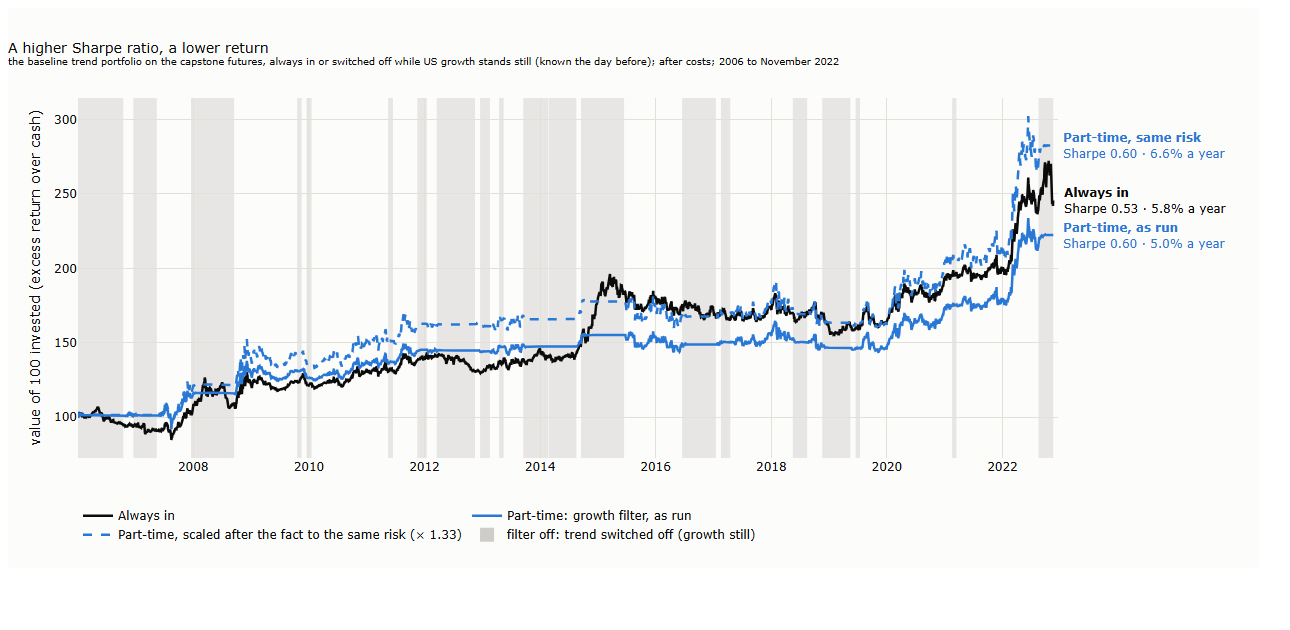

In [4]:
run("l28_key_chart.py")
pictures("28_key")

### 1.1 The switch by hand

Off means a target scale of 0, on a scale of 1; the scale moves a tenth of the way each day and every change costs 5 bp of the gross exposure moved. Written as a plain loop, against the compiled `switched` of `l28_filters.py`.

In [5]:
base = B["futures"].dropna().loc[L.FUT_START:L.END["futures"]]
G = pd.read_parquet(L.OUT / "l28_regimes_futures.parquet").reindex(base.index)
off = LF.offs(G, LF.FIXED)["growth"]
s, out = 1.0, []
for r_, g_, o in zip(base.ret, base.gross, off):
    new = s + L.LAMBDA * ((0.0 if o else 1.0) - s)
    out.append(new * r_ - L.COST_BP / 1e4 * abs(new - s) * g_); s = new
part = pd.Series(out, base.index)
lib = LF.switched(base.ret.to_numpy(), base.gross.to_numpy(), off.to_numpy(), L.LAMBDA, L.COST_BP / 1e4)
print(f"growth filter off on {off.mean():.0%} of days; largest daily difference from the library: {np.abs(part.to_numpy() - lib).max():.1e}")

growth filter off on 41% of days; largest daily difference from the library: 0.0e+00


## 2. Comparing part-time with always-in

### 2.1 The six numbers by hand

The running example of §2.3: Sharpe ratio over all days and while on, volatility, return as run and scaled to the same risk, worst drawdown, alpha over always-in (intercept of a regression on always-in's daily returns).

In [6]:
dd = lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()
k = base.ret.std() / part.std()
X = np.column_stack([np.ones(len(part)), base.ret.to_numpy()]); beta = np.linalg.lstsq(X, part.to_numpy(), rcond=None)[0]
resid = part.to_numpy() - X @ beta; t_alpha = beta[0] / np.sqrt(resid.var(ddof=2) / len(part))
six = pd.DataFrame({"always in": {"share of days on": 1.0, "Sharpe, while on": L26.sharpe(base.ret), "Sharpe, all days": L26.sharpe(base.ret),
                                  "volatility": base.ret.std() * np.sqrt(252), "return a year, as run": base.ret.mean() * 252,
                                  "return a year, same risk": base.ret.mean() * 252, "worst drawdown, as run": dd(base.ret), "worst drawdown, same risk": dd(base.ret)},
                    "growth filter": {"share of days on": 1 - off.mean(), "Sharpe, while on": L26.sharpe(base.ret[~off]), "Sharpe, all days": L26.sharpe(part),
                                      "volatility": part.std() * np.sqrt(252), "return a year, as run": part.mean() * 252,
                                      "return a year, same risk": (part * k).mean() * 252, "worst drawdown, as run": dd(part), "worst drawdown, same risk": dd(part * k)}})
display(six.round(3))
print(f"scale to the same risk: x {k:.2f}; alpha {beta[0] * 252:.2%} a year, t-statistic {t_alpha:.2f}")
m = result("filters.json", SHIPPED)["datasets"]["futures"]["growth"]["0.33"]
print(f"shipped: Sharpe {m['sharpe']:.3f}, while on {m['sharpe_on']:.3f}, alpha {m['alpha']:.2%} (t {m['alpha_t']:.2f})")

,always in,growth filter
share of days on,1.000,0.594
"Sharpe, while on",0.526,0.666
"Sharpe, all days",0.526,0.600
volatility,0.110,0.083
"return a year, as run",0.058,0.050
"return a year, same risk",0.058,0.066
"worst drawdown, as run",-0.209,-0.127
"worst drawdown, same risk",-0.209,-0.168


scale to the same risk: x 1.33; alpha 1.51% a year, t-statistic 1.24
shipped: Sharpe 0.600, while on 0.666, alpha 1.51% (t 1.24)


### 2.2 Random filters by hand, and the square-root link

Random switches with the same share of time off and the same average spell lengths: a two-state Markov chain, leaving the off state with probability one over the mean off spell and the on state with one over the mean on spell. 200 draws here (the lecture uses 1,000), so the median and 95th percentile differ slightly from the shipped ones. Lecture 7's link: with no information, Sharpe over all days is about Sharpe while on times the square root of the share of days on.

In [7]:
lo, ln = LF.spells(off); rng = np.random.default_rng(1); sh = []
for _ in range(200):
    st = rng.random() < off.mean(); x = np.empty(len(off), dtype=bool); u = rng.random(len(off))
    for i in range(len(off)):
        x[i] = st; st = (not (u[i] < 1 / lo)) if st else (u[i] < 1 / ln)
    sh.append(L26.sharpe(pd.Series(LF.switched(base.ret.to_numpy(), base.gross.to_numpy(), x, L.LAMBDA, L.COST_BP / 1e4))))
sh = np.array(sh); p = 1 - off.mean()
print(f"mean spells: off {lo:.0f} days, on {ln:.0f} days")
print(f"random filters: median {np.median(sh):.3f}, 95th percentile {np.quantile(sh, .95):.3f}; the filter beats {(L26.sharpe(part) > sh).mean():.0%} (shipped: {m['random_median']:.3f}, {m['random_p95']:.3f}, {m['beaten']:.0%})")
print(f"square-root link: always-in {L26.sharpe(base.ret):.3f} x sqrt({p:.2f}) = {L26.sharpe(base.ret) * np.sqrt(p):.3f}, against the random median {np.median(sh):.3f}")
print("Sharpe ratio needed while on to match always-in:", {f"{q:.0%}": round(float(1 / np.sqrt(q)), 2) for q in (0.9, 0.75, 0.6, 0.5)})

mean spells: off 89 days, on 136 days
random filters: median 0.394, 95th percentile 0.616; the filter beats 92% (shipped: 0.408, 0.599, 95%)
square-root link: always-in 0.526 x sqrt(0.59) = 0.406, against the random median 0.394
Sharpe ratio needed while on to match always-in: {'90%': 1.05, '75%': 1.15, '60%': 1.29, '50%': 1.41}


## 3. Data as first published

On each day, the growth × inflation quadrant (the sign of each 12-month change) from the vintage available that day and from today's revised data; the share of days on which they differ, and the trend portfolio's Sharpe ratio by quadrant on each.

In [8]:
for tag, start in (("etf", L.ETF_START), ("futures", L.FUT_START)):
    b = B[tag].dropna().loc[start:L.END[tag]]; R = pd.read_parquet(L.OUT / f"l28_regimes_{tag}.parquet").reindex(b.index)
    q = {src: (np.sign(R[(f"growth{src}", "sign")]).astype(str) + np.sign(R[(f"inflation{src}", "sign")]).astype(str)) for src in ("", "_revised")}
    ok = R[("growth", "sign")].notna() & R[("growth_revised", "sign")].notna() & R[("inflation", "sign")].notna() & R[("inflation_revised", "sign")].notna()
    print(f"{tag}: {(q[''] != q['_revised'])[ok].mean():.1%} of days in a different quadrant (shipped: {result('scan.json', SHIPPED)[tag]['quadrant_disagreement']:.1%})")
S = result("scan.json", SHIPPED)
display(pd.DataFrame({f"{tag}, {src.replace('quadrant_', '').replace('_', ' ')}": {q: v["sharpe"] for q, v in S[tag][src].items()}
                      for tag in ("etf", "futures") for src in ("quadrant_first_published", "quadrant_revised")}).round(2))

etf: 18.6% of days in a different quadrant (shipped: 18.6%)
futures: 22.0% of days in a different quadrant (shipped: 22.0%)


,"etf, first published","etf, revised","futures, first published","futures, revised"
"growth down, inflation down",0.50,0.26,0.08,0.08
"growth down, inflation up",0.12,-0.04,1.12,0.41
"growth up, inflation down",0.26,0.28,0.37,0.32
"growth up, inflation up",0.77,1.17,0.46,1.18


## 4. The scan

Per variable, the baseline's Sharpe ratio on the days the filter would keep trend on and on the days it would switch trend off, and the difference with its 90% band. Nothing is switched.

l28_charts.py : 8 s


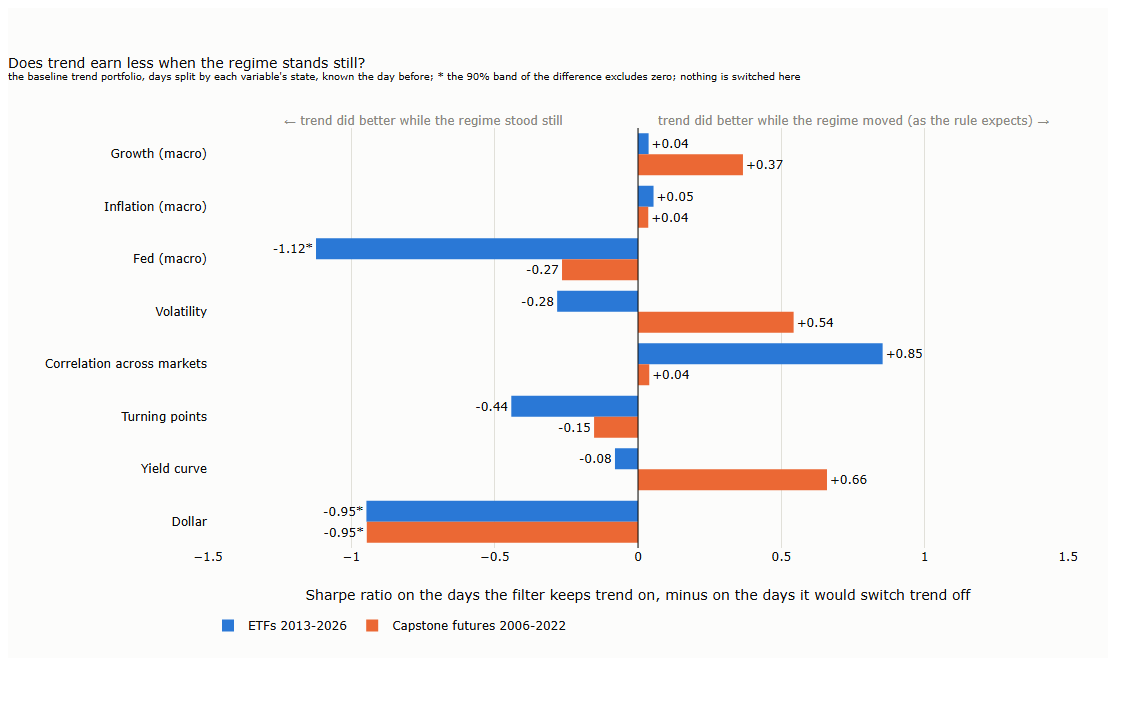

,etf: sharpe_on,etf: sharpe_off,etf: diff,etf: band,futures: sharpe_on,futures: sharpe_off,futures: diff,futures: band
growth,0.50,0.47,0.04,-0.82 to +0.97,0.67,0.32,0.35,-0.46 to +1.13
inflation,0.50,0.45,0.05,-0.89 to +1.08,0.55,0.45,0.11,-0.85 to +0.96
fed,0.01,1.13,-1.12,-1.95 to -0.32,0.36,0.70,-0.34,-1.06 to +0.37
volatility,0.38,0.67,-0.28,-1.14 to +0.56,0.74,0.25,0.50,-0.28 to +1.25
correlation,0.59,-0.26,0.85,-1.65 to +2.58,0.72,0.30,0.42,-0.33 to +1.19
turning,0.34,0.78,-0.44,-1.49 to +0.49,0.41,0.67,-0.26,-1.06 to +0.49
curve,0.46,0.54,-0.08,-1.08 to +0.89,0.71,0.07,0.64,-0.16 to +1.41
dollar,0.11,1.06,-0.95,-1.77 to -0.08,0.28,1.31,-1.03,-1.81 to -0.30


In [9]:
run("l28_charts.py")
pictures("28_scan")
display(pd.DataFrame({f"{tag}: {c}": {k: (v[c] if c != "band" else f"{v['ci90'][0]:+.2f} to {v['ci90'][1]:+.2f}") for k, v in S[tag].items() if isinstance(v, dict) and "diff" in v}
                      for tag in ("etf", "futures") for c in ("sharpe_on", "sharpe_off", "diff", "band")}).round(2))

## 5. The filters against luck

Each filter at its fixed threshold: share of days on, Sharpe ratio over all days, the share of its 1,000 random filters it beats, and the threshold grid.

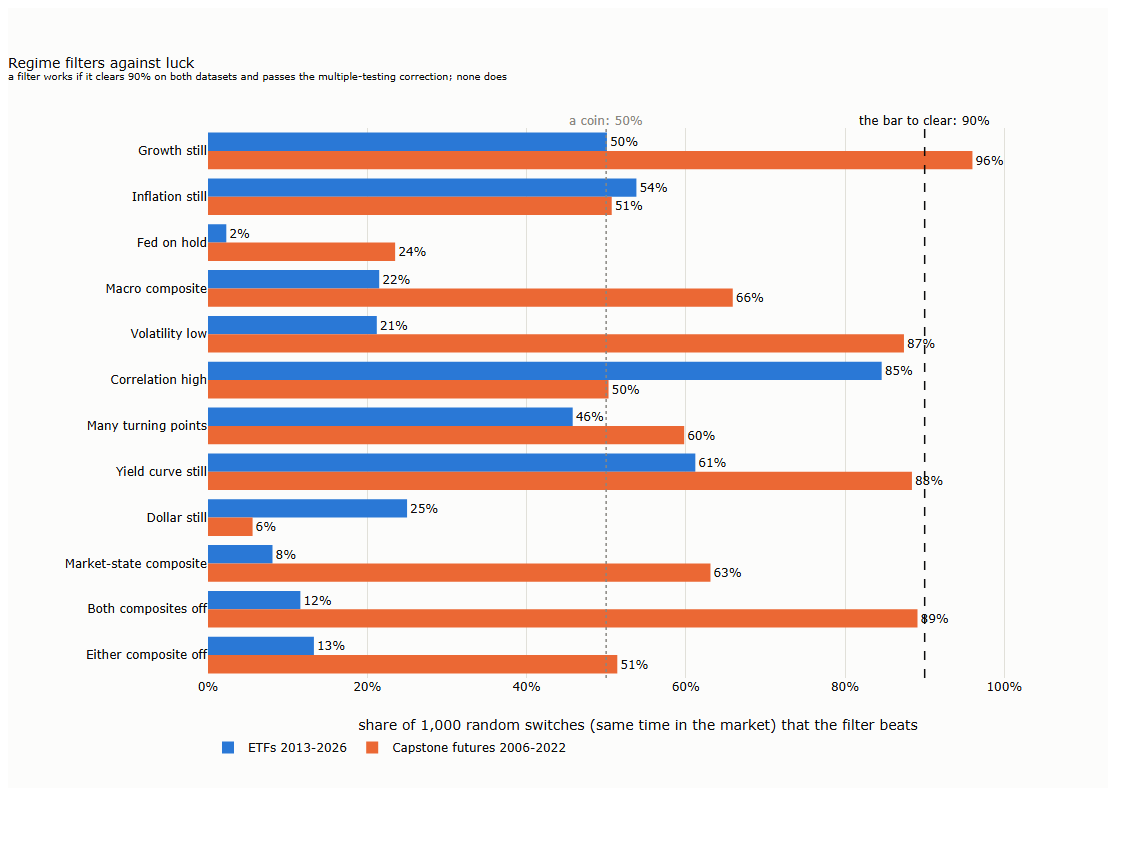

,etf: share_on,etf: sharpe,etf: beaten,futures: share_on,futures: sharpe,futures: beaten
Growth still,0.54,0.33,0.50,0.59,0.60,0.95
Inflation still,0.66,0.37,0.54,0.76,0.47,0.55
Fed on hold,0.55,-0.05,0.02,0.45,0.18,0.21
Macro composite,0.59,0.21,0.22,0.66,0.46,0.62
Volatility low,0.59,0.19,0.21,0.51,0.51,0.82
Correlation high,0.91,0.52,0.85,0.54,0.47,0.72
Many turning points,0.68,0.23,0.46,0.50,0.35,0.63
Yield curve still,0.72,0.37,0.61,0.67,0.54,0.87
Dollar still,0.59,0.17,0.25,0.69,0.24,0.04
Market-state composite,0.80,0.25,0.08,0.65,0.43,0.66


,etf: 0.25,etf: 0.33,etf: 0.50,futures: 0.25,futures: 0.33,futures: 0.50,etf: quarter,etf: third,etf: half,futures: quarter,futures: third,futures: half,etf: 0.75,etf: 0.67,futures: 0.75,futures: 0.67
Growth still,0.32,0.33,0.18,0.51,0.60,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inflation still,0.41,0.37,0.30,0.53,0.47,0.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fed on hold,NaN,NaN,NaN,NaN,NaN,NaN,-0.05,-0.05,-0.05,0.18,0.18,0.18,NaN,NaN,NaN,NaN
Macro composite,NaN,NaN,NaN,NaN,NaN,NaN,0.20,0.21,0.10,0.47,0.46,0.44,NaN,NaN,NaN,NaN
Volatility low,0.35,0.19,-0.12,0.54,0.51,0.42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Correlation high,NaN,NaN,0.51,NaN,NaN,0.37,NaN,NaN,NaN,NaN,NaN,NaN,0.48,0.52,0.49,0.47
Many turning points,NaN,NaN,0.18,NaN,NaN,0.29,NaN,NaN,NaN,NaN,NaN,NaN,0.33,0.23,0.41,0.35
Yield curve still,0.35,0.37,0.39,0.45,0.54,0.61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dollar still,0.25,0.17,0.13,0.32,0.24,0.23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Market-state composite,NaN,NaN,NaN,NaN,NaN,NaN,0.31,0.25,0.15,0.42,0.43,0.36,NaN,NaN,NaN,NaN


In [10]:
pictures("28_filters")
FR = result("filters.json", SHIPPED); fx = lambda k: LF.LEVELS[LF.KIND[k]][LF.FIXED] if k in LF.KIND else "third"
ks = [k for v in LF.FAMILIES.values() for k in v]
display(pd.DataFrame({LF.NAMES[k]: {f"{t}: {c}": FR["datasets"][t][k][fx(k)][c] for t in ("etf", "futures") for c in ("share_on", "sharpe", "beaten")} for k in ks}).T.round(2))
display(pd.DataFrame({LF.NAMES[k]: {f"{t}: {lev}": v["sharpe"] for t in ("etf", "futures") for lev, v in FR["datasets"][t][k].items()} for k in ks}).T.round(2))

### 5.1 Benjamini-Hochberg by hand

Within each family, each filter's p-value is the larger of its two (one minus the share of random filters beaten, on the ETFs and on the futures). Sorted from smallest, the $`i`$-th of $`m`$ passes if it and some larger one are at most $`0.10 \cdot i / m`$.

In [11]:
for fam, ks_ in LF.FAMILIES.items():
    p = pd.Series({k: max(1 - FR["datasets"][t][k][fx(k)]["beaten"] for t in ("etf", "futures")) for k in ks_}).sort_values()
    limit = 0.10 * np.arange(1, len(p) + 1) / len(p); passing = np.flatnonzero(p.to_numpy() <= limit)
    n = passing.max() + 1 if len(passing) else 0
    print(f"{fam}: " + ", ".join(f"{LF.NAMES[k]} p={v:.3f} (limit {l:.3f})" for (k, v), l in zip(p.items(), limit)) + f" -> {n} pass; shipped: {sum(v['bh'] for v in FR['verdict'][fam].values())}")

macro: Inflation still p=0.462 (limit 0.025), Growth still p=0.499 (limit 0.050), Macro composite p=0.785 (limit 0.075), Fed on hold p=0.977 (limit 0.100) -> 0 pass; shipped: 0
market state: Correlation high p=0.277 (limit 0.017), Yield curve still p=0.388 (limit 0.033), Many turning points p=0.542 (limit 0.050), Volatility low p=0.788 (limit 0.067), Market-state composite p=0.919 (limit 0.083), Dollar still p=0.961 (limit 0.100) -> 0 pass; shipped: 0
both: Either composite off p=0.867 (limit 0.050), Both composites off p=0.884 (limit 0.100) -> 0 pass; shipped: 0


## 6. Why: exploring the patterns

### 6.1 Fed and dollar; level and direction

Which years and classes gave the Fed and dollar patterns (ETFs), and the baseline by the level (fifth of its history to date) and direction of volatility and correlation.

l28_why.py : 5 s


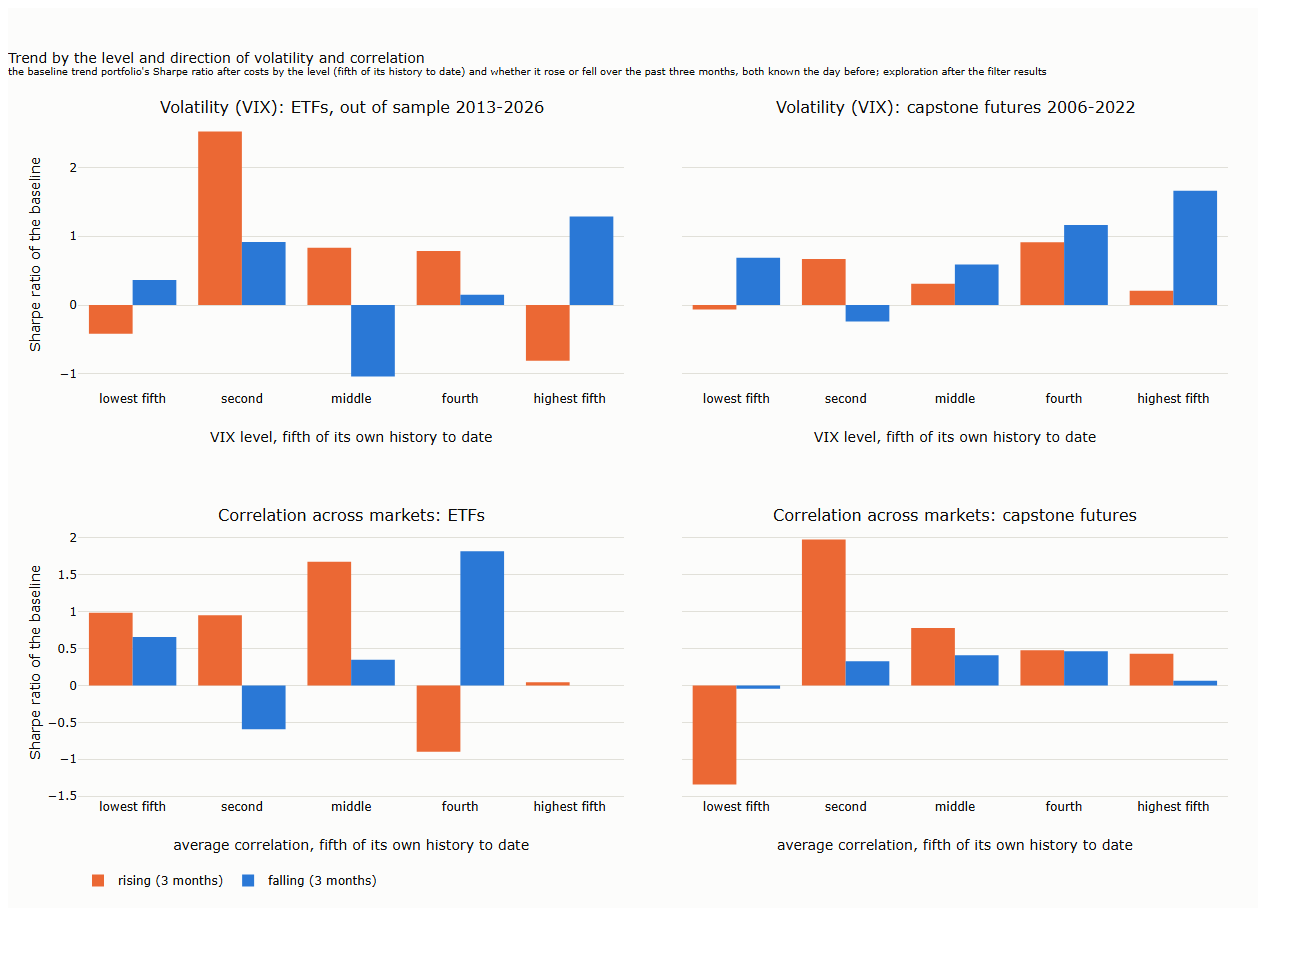

fed


,share_still,ret_still,ret_moving
2013,1.000,0.055,0.000
2014,1.000,0.249,0.000
2015,0.960,0.112,-0.021
2016,0.500,-0.011,-0.008
2017,0.000,0.000,0.050
2018,0.000,0.000,-0.084
2019,0.111,0.038,0.097
2020,0.296,0.041,-0.031
2021,1.000,0.040,0.000
2022,0.207,0.029,0.133


dollar


,share_still,ret_still,ret_moving
2013,0.853,0.017,0.038
2014,0.516,0.111,0.137
2015,0.000,0.000,0.091
2016,0.250,-0.006,-0.013
2017,0.474,0.073,-0.024
2018,0.259,0.016,-0.100
2019,0.484,0.144,-0.009
2020,0.542,0.055,-0.045
2021,0.238,0.050,-0.010
2022,0.147,0.087,0.076


In [12]:
run("l28_why.py")
pictures("28_volatility")
W = result("why.json", SHIPPED)
for k in ("fed", "dollar"):
    print(k); display(pd.DataFrame(W["etf"][k]["years"]).T.round(3))

### 6.2 Four quadrants, the clock and the timeline

The quadrant chart (the ETFs, the futures and 1990-2005), the volatility clock and the regime timeline. Then one cell by hand: the futures baseline on the days the VIX was above its average to date and had fallen over three months.

l28_quadrants.py : 5 s


l28_regime_charts.py : 6 s


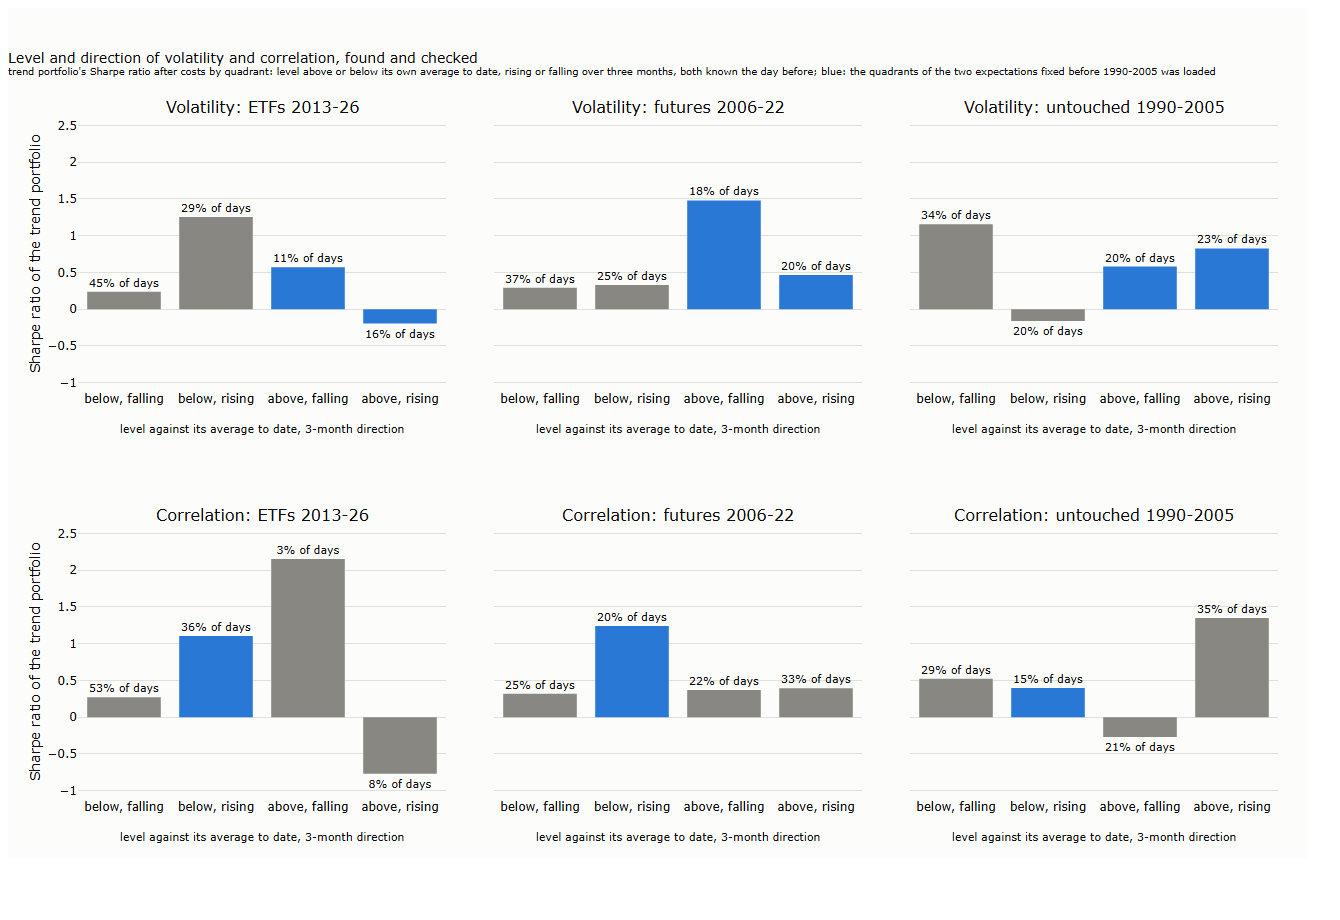

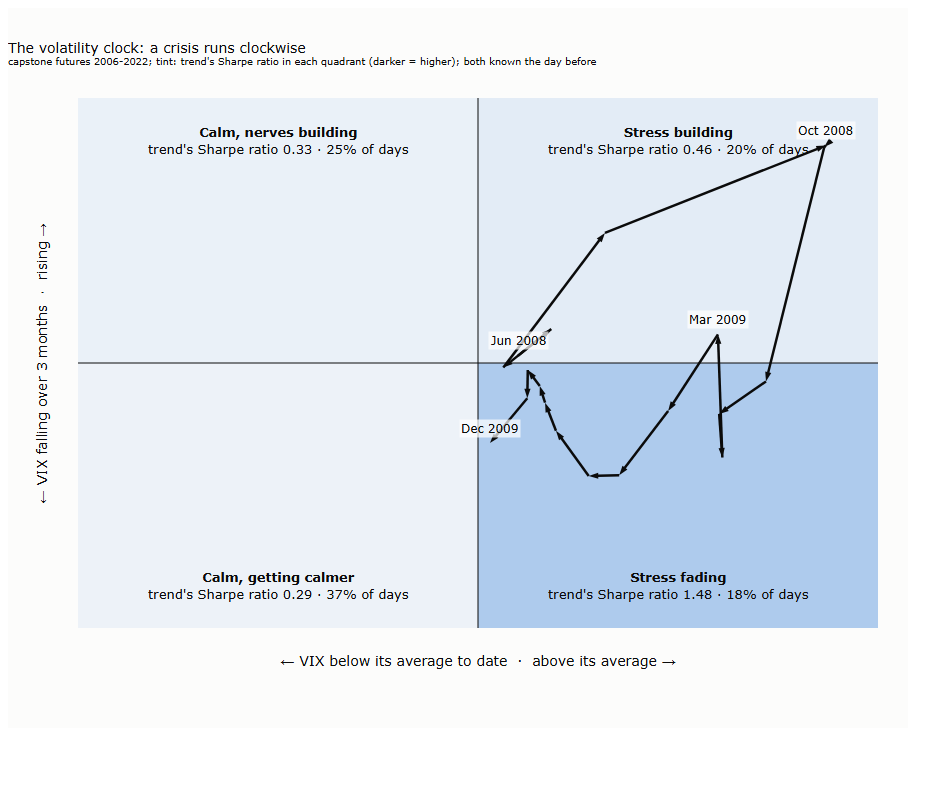

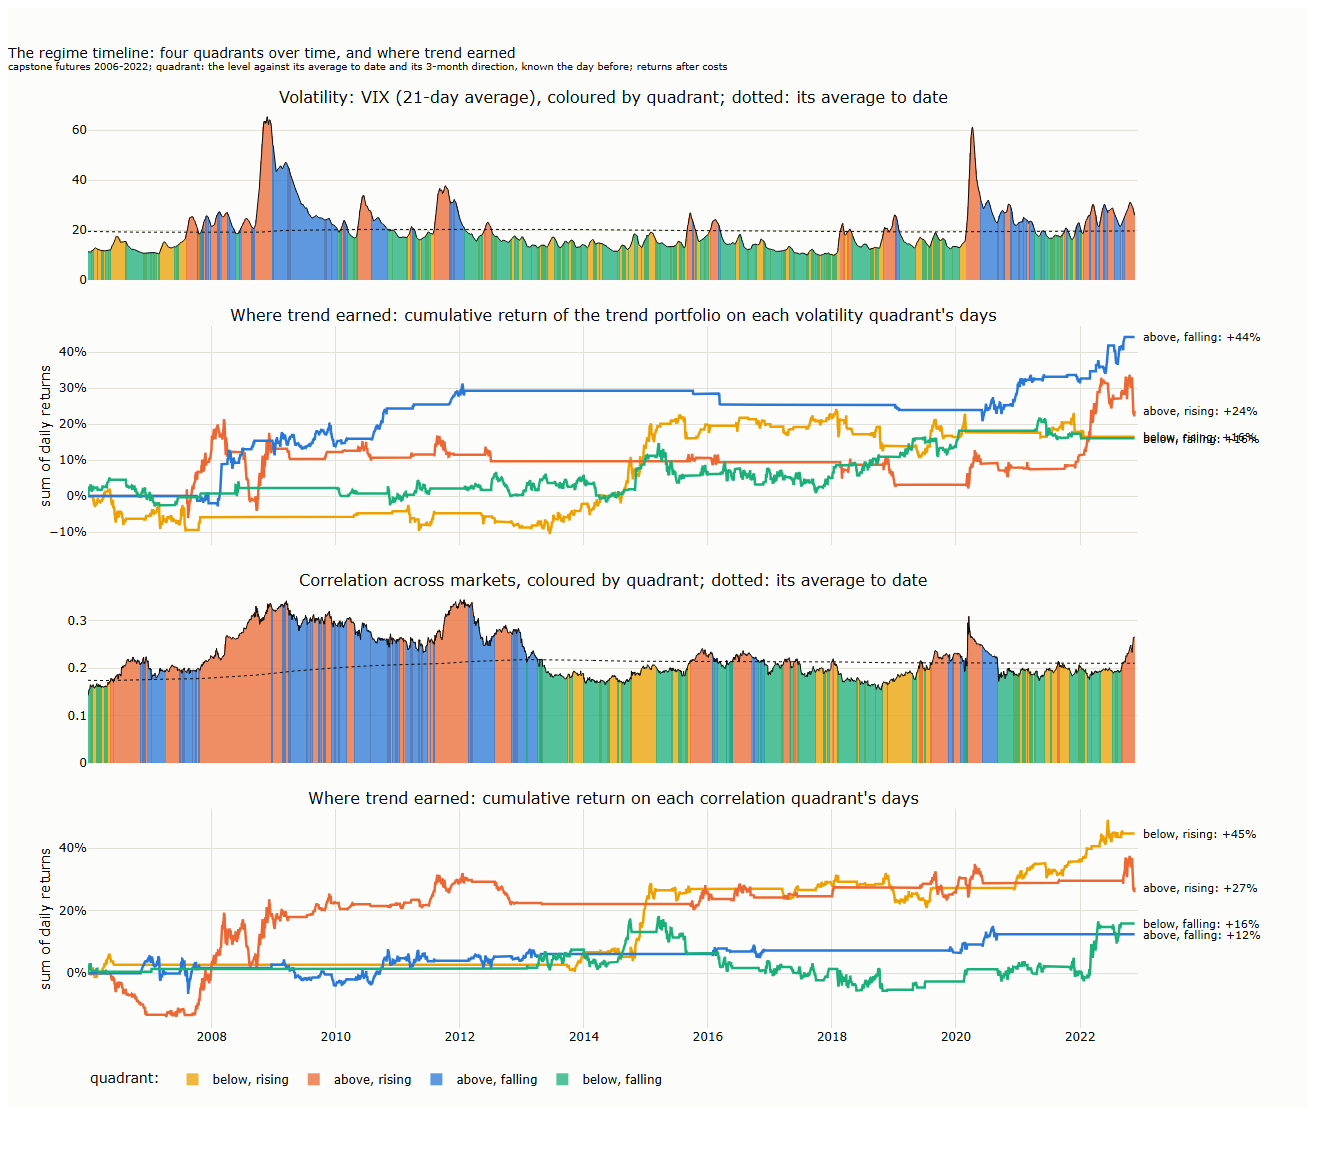

above average and falling: 17.8% of days, Sharpe ratio 1.479 (shipped: 1.479)


In [13]:
run("l28_quadrants.py"); run("l28_regime_charts.py")
pictures("28_quadrants", "28_clock", "28_timeline")
vix = L.fred("VIXCLS").reindex(pd.bdate_range("1990-01-01", base.index[-1])).ffill()
lvl = vix.rolling(21).mean().shift(1); avg = lvl.expanding(1260).mean(); chg = (np.log(vix) - np.log(vix.shift(63))).shift(1)
cell = ((lvl > avg) & (chg < 0)).reindex(base.index, fill_value=False).astype(bool)
print(f"above average and falling: {cell.mean():.1%} of days, Sharpe ratio {L26.sharpe(base.ret[cell]):.3f} (shipped: {result('quadrants.json', SHIPPED)['futures']['volatility']['above falling']['sharpe']:.3f})")

### 6.3 The check on 1990-2005

The two statements fixed before these years were loaded, and what happened (`l28_confirm.py` builds the 12-market portfolio from free long series).

In [14]:
CF = result("confirm.json", SHIPPED)
print(f"1990-2005 portfolio: {len(CF['markets'])} markets, Sharpe ratio {CF['sharpe']:.2f}")
display(pd.DataFrame({k: {q: f"{v['sharpe']:+.2f} ({v['share']:.0%})" for q, v in CF[k].items()} for k in ("volatility", "correlation")}))
print("E1:", CF["E1"]); print("E2:", CF["E2"])

1990-2005 portfolio: 12 markets, Sharpe ratio 0.64


,volatility,correlation
below falling,+1.15 (34%),+0.52 (29%)
below rising,-0.16 (20%),+0.40 (15%)
above falling,+0.58 (20%),-0.27 (21%)
above rising,+0.82 (23%),+1.35 (35%)


E1: {'best_quadrant': 'above rising', 'holds': False, 'diff_vs_rest': -0.29276638618337225, 'ci90': [-1.5533881104512566, 0.9653217458587445]}
E2: {'above_falling': 0.5797949312365321, 'above_rising': 0.8249234452557271, 'holds': False, 'ci90': [-1.4259464105363728, 0.986520736909206]}


## 7. Commodity curves

Each commodity's trend stream in backwardation and in contango, and the sleeve. Then one curve gap by hand: crude oil on 1 July 2008, from the contract files.

l28_curves.py : 38 s


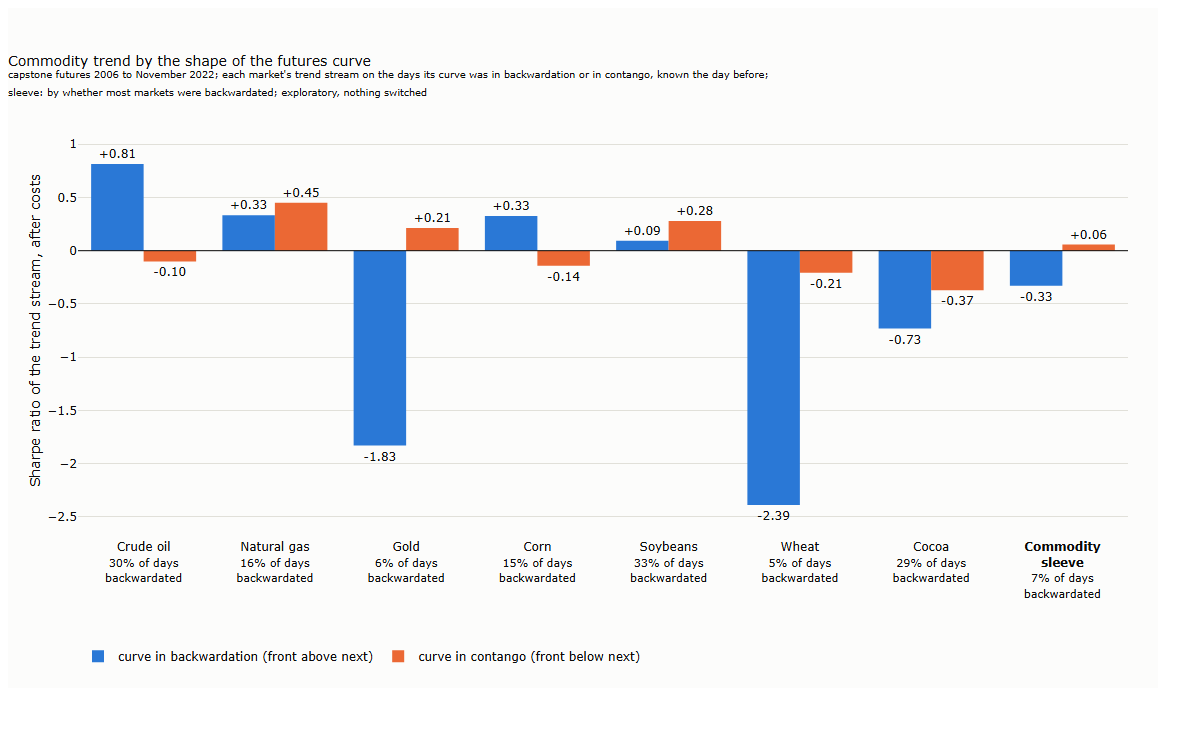

front CME_CLQ2008.csv 140.97, next CME_CLU2008.csv 141.58: annualised gap -5.4% (contango); library: -5.4%


,name,share_back,sharpe_back,sharpe_contango
nymex-cl,Crude oil,0.297436,0.813658,-0.101423
nymex-ng,Natural gas,0.159202,0.332982,0.450399
comex-gc,Gold,0.05981,-1.831517,0.213816
cbot-corn,Corn,0.153448,0.325937,-0.141885
cbot-soybeans,Soybeans,0.32841,0.092457,0.278339
cbot-wheat,Wheat,0.052217,-2.389978,-0.207393
ice-cocoa,Cocoa,0.29383,-0.731369,-0.372125


In [15]:
if FUTURES:
    run("l28_curves.py"); pictures("28_curves")
    import l28_curves as CV
    day = pd.Timestamp("2008-07-01"); C_ = []
    for f in (CV.KAGGLE / "nymex-cl").glob("*.csv"):
        mm = re.search(r"([FGHJKMNQUVXZ])(\d{4})\.csv$", f.name); x = pd.read_csv(f, index_col=0, parse_dates=True)["Close"].sort_index().dropna()
        if len(x) > 20: C_.append((int(mm.group(2)) * 12 + CV.CODES.index(mm.group(1)), f.name, x))
    C_.sort(key=lambda c: c[0])
    i = next(j for j, c in enumerate(C_) if c[2].index[-1] > day + pd.offsets.BDay(5))
    (_, fa, a), (_, fb, b) = C_[i], C_[i + 1]
    gap = np.log(a.loc[day] / b.loc[day]) * 365 / (b.index[-1] - a.index[-1]).days
    print(f"front {fa} {a.loc[day]:.2f}, next {fb} {b.loc[day]:.2f}: annualised gap {gap:+.1%} ({'backwardation' if gap > 0 else 'contango'}); library: {CV.curve('nymex-cl').loc[day]:+.1%}")
    display(pd.DataFrame(result("curves.json", SHIPPED)["markets"]).T[["name", "share_back", "sharpe_back", "sharpe_contango"]])
else: print("capstone futures not found: §7 skipped")

## 8. Shipped against recomputed

With `RUN_ALL`, the rerun's key numbers against the shipped results. With the same downloads they match; a later download can differ slightly, since Yahoo revises adjusted prices and FRED revises some series.

In [16]:
rows = [dict(number=f"{t}: always in, Sharpe", shipped=result("filters.json", SHIPPED)["datasets"][t]["baseline"]["sharpe"], recomputed=result("filters.json")["datasets"][t]["baseline"]["sharpe"]) for t in ("etf", "futures")]
rows += [dict(number=f"{t}: growth still, random filters beaten", shipped=result("filters.json", SHIPPED)["datasets"][t]["growth"]["0.33"]["beaten"], recomputed=result("filters.json")["datasets"][t]["growth"]["0.33"]["beaten"]) for t in ("etf", "futures")]
rows += [dict(number="1990-2005: Sharpe", shipped=result("confirm.json", SHIPPED)["sharpe"], recomputed=result("confirm.json")["sharpe"])]
pd.DataFrame(rows).round(4)

,number,shipped,recomputed
0,"etf: always in, Sharpe",0.4862,0.4862
1,"futures: always in, Sharpe",0.5262,0.5533
2,"etf: growth still, random filters beaten",0.5010,0.5010
3,"futures: growth still, random filters beaten",0.9500,0.9600
4,1990-2005: Sharpe,0.6414,0.6414


**A test of your own.** Fix a regime variable and its unfavourable state with a reason, before looking: for example the size of the 12-month change in oil prices, or the share of markets at a 12-month high. Add it to `market_state` in `scripts/l28.py` and to `KIND` in `scripts/l28_filters.py`, rerun with `RUN_ALL`, and judge it by the six numbers of §2 and against its random filters on both datasets. Date the plan in `results/hypotheses.md` before you run it, as every step of this lecture was.